In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random
from copy import deepcopy
import re
from sklearn.metrics import mean_squared_error

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import numpy as np
from dotenv import load_dotenv
from natsort import natsorted

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [2]:
runs_to_download = []

for parent_run_id in ['f02bf732b2ba4817b254bd5174f1549b', 'f862625665764f1383bf88e5615594dc', '6a8078c2c7764850b1fb8b3c33553a1b']:
  runs_to_download.extend(mlflow.search_runs(
      filter_string=f"attributes.status = 'FINISHED' and params.model_class = 'HybridModel' and tags.mlflow.parentRunId ='{parent_run_id}'",
        experiment_ids=['6'], output_format='list'))

  runs_to_download.extend(mlflow.search_runs(
      filter_string=f"attributes.status = 'FINISHED' and params.model_class = 'PyTorchODE' and tags.mlflow.parentRunId ='{parent_run_id}'",
        experiment_ids=['10'], output_format='list'))

print(len(runs_to_download))

34


In [3]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-06-18 09:08:55,889 - INFO - Downloading artifacts for run 4ce2c0cbe5454315b45fb0277d11fd12
2026-06-18 09:09:06,405 - INFO - Downloading artifacts for run 1cd5efb3ef374f51ad9a5ced5e80d541
2026-06-18 09:09:11,008 - INFO - Downloading artifacts for run 5922b969bd6942d0bf5e7bf6901952e9
2026-06-18 09:09:12,670 - INFO - Downloading artifacts for run e6f120fab5b24d2ba199a4a7fa78ec25
2026-06-18 09:09:14,256 - INFO - Downloading artifacts for run c24b7e48838c4020830d1f4bd8cd5232
2026-06-18 09:09:15,843 - INFO - Downloading artifacts for run c9857f735210428096ed4742d4b1774d
2026-06-18 09:09:17,284 - INFO - Downloading artifacts for run 427ae5b0df6d4b8db7c0c8000291309b
2026-06-18 09:09:18,887 - INFO - Downloading artifacts for run e2efeb50d80947b0936353f6c4bd688a
2026-06-18 09:09:20,337 - INFO - Downloading artifacts for run bc5518f4c35b43ef90289ec96051ce3f
2026-06-18 09:09:21,785 - INFO - Downloading artifacts for run 69793937e2a741a594b1a119f16afa13
2026-06-18 09:09:23,257 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b


In [4]:
raw_predictions_df.shape

(4842432, 7)

In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."


In [6]:
records = []
gene_network_dict = dict()
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    gene_network_dict[mlflow.get_run(run_id).data.params['nr_genes']] = sim_output.network
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)
gene_network_dict

2026-06-18 09:10:13,297 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,306 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,314 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,325 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,339 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,352 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,366 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 09:10:13,379 - WARNING - Connection p

{'50': <halcyon.Datasets.RegulatoryNetwork.RegulatoryNetwork at 0x7f9417e1a1a0>,
 '100': <halcyon.Datasets.RegulatoryNetwork.RegulatoryNetwork at 0x7f94160ec040>,
 '20': <halcyon.Datasets.RegulatoryNetwork.RegulatoryNetwork at 0x7f9418bdfee0>}

In [7]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,f02bf732b2ba4817b254bd5174f1549b,50
1,f862625665764f1383bf88e5615594dc,100
2,6a8078c2c7764850b1fb8b3c33553a1b,20


In [8]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

outcome.head()

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation,nr_genes
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,f02bf732b2ba4817b254bd5174f1549b,50
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,f02bf732b2ba4817b254bd5174f1549b,50
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,f02bf732b2ba4817b254bd5174f1549b,50
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,f02bf732b2ba4817b254bd5174f1549b,50
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,f02bf732b2ba4817b254bd5174f1549b,50


In [9]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

In [10]:
outcome['model_name'].unique()

array(['HybridModel', 'PyTorchODE'], dtype=object)

In [11]:
stdev_df = outcome.groupby(['gene', 'condition', 'nr_genes'])['noiseless_ground_truth'].std().reset_index().rename(
    columns={'noiseless_ground_truth': 'gene_expression_stdev'})
stdev_df.head()

,gene,condition,nr_genes,gene_expression_stdev
0,Node_0,"KO: Node_0, Node_1. Env: None",20,0.194000
1,Node_0,"KO: Node_0, Node_13. Env: None",20,0.197007
2,Node_0,"KO: Node_0, Node_13. Env: None",50,0.023130
3,Node_0,"KO: Node_0, Node_19. Env: None",100,0.137513
4,Node_0,"KO: Node_0, Node_19. Env: None",50,0.022173


In [12]:
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes
0,Node_0,0.0,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,50
1,Node_1,0.0,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,50
2,Node_2,0.0,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,50
3,Node_3,0.0,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,50
4,Node_4,0.0,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,50
...,...,...,...,...,...,...,...,...,...
4842427,Node_10,1.0,1.000000,"KO: Node_0, Node_1. Env: None",a7274467c4464616b899c3ce926a87c1,PyTorchODE,"['Node_9', 'Node_1', 'Node_5', 'Node_13', 'Nod...",1.025268,20
4842428,Node_14,1.0,0.671323,"KO: Node_0, Node_1. Env: None",a7274467c4464616b899c3ce926a87c1,PyTorchODE,"['Node_9', 'Node_1', 'Node_5', 'Node_13', 'Nod...",0.657183,20
4842429,Node_15,1.0,0.167993,"KO: Node_0, Node_1. Env: None",a7274467c4464616b899c3ce926a87c1,PyTorchODE,"['Node_9', 'Node_1', 'Node_5', 'Node_13', 'Nod...",0.214716,20
4842430,Node_16,1.0,0.873942,"KO: Node_0, Node_1. Env: None",a7274467c4464616b899c3ce926a87c1,PyTorchODE,"['Node_9', 'Node_1', 'Node_5', 'Node_13', 'Nod...",0.946312,20


In [13]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [14]:
double_ko_df.head()

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes
39900,Node_0,0.0,0.000000,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.102054,50
39901,Node_1,0.0,0.540319,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.520959,50
39902,Node_2,0.0,0.744383,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.628458,50
39903,Node_3,0.0,0.190828,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.398028,50
39904,Node_4,0.0,0.450183,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.271006,50


In [15]:
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
        lambda row: lookup[(
            row['condition'],
            row['modelled_genes'] if row['modelled_genes'] is not None else None
        )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [16]:
groupby_list = [
    'model_name',
    'modelled_genes',
    'nr_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mm_mse = mse_df[mse_df['model_name'] == 'PyTorchODE'][['gene', 'condition', 'MSE', 'modelled_genes', 'nr_genes']].rename(columns={'MSE': 'mm_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'MSE', 'modelled_genes', 'nr_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mm_mse, on=['gene', 'condition', 'modelled_genes', 'nr_genes'])


In [17]:
paired = annotate_kos_in_df(paired)
paired

,gene,condition,hybrid_mse,modelled_genes,nr_genes,mm_mse,ko_in_mm,gene_in_mm
0,Node_1,"KO: Node_0, Node_8. Env: None",0.007176,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.016326,partially,True
1,Node_1,"KO: Node_1, Node_11. Env: None",0.030604,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001076,fully,True
2,Node_1,"KO: Node_1, Node_13. Env: None",0.033340,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001958,partially,True
3,Node_1,"KO: Node_1, Node_15. Env: None",0.033538,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.002145,fully,True
4,Node_1,"KO: Node_1, Node_16. Env: None",0.027491,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.000792,fully,True
...,...,...,...,...,...,...,...,...
2199,Node_9,"KO: Node_8, Node_9. Env: None",0.024686,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001265,partially,True
2200,Node_9,"KO: Node_9, Node_21. Env: None",0.027559,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001672,fully,True
2201,Node_9,"KO: Node_9, Node_26. Env: None",0.029019,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.002661,partially,True
2202,Node_9,"KO: Node_9, Node_41. Env: None",0.026530,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.000980,fully,True


In [18]:
paired = pd.merge(paired, stdev_df, 'left', on=['gene', 'condition', 'nr_genes'])
paired

,gene,condition,hybrid_mse,modelled_genes,nr_genes,mm_mse,ko_in_mm,gene_in_mm,gene_expression_stdev
0,Node_1,"KO: Node_0, Node_8. Env: None",0.007176,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.016326,partially,True,0.126564
1,Node_1,"KO: Node_1, Node_11. Env: None",0.030604,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001076,fully,True,0.036016
2,Node_1,"KO: Node_1, Node_13. Env: None",0.033340,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001958,partially,True,0.041300
3,Node_1,"KO: Node_1, Node_15. Env: None",0.033538,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.002145,fully,True,0.043365
4,Node_1,"KO: Node_1, Node_16. Env: None",0.027491,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.000792,fully,True,0.046109
...,...,...,...,...,...,...,...,...,...
2199,Node_9,"KO: Node_8, Node_9. Env: None",0.024686,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001265,partially,True,0.095967
2200,Node_9,"KO: Node_9, Node_21. Env: None",0.027559,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001672,fully,True,0.099060
2201,Node_9,"KO: Node_9, Node_26. Env: None",0.029019,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.002661,partially,True,0.098897
2202,Node_9,"KO: Node_9, Node_41. Env: None",0.026530,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.000980,fully,True,0.097083


In [19]:
import string
genes_to_letter_map = {}
i = 0
for genes in paired['modelled_genes'].unique():
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
    i += 1
genes_to_letter_map

{"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'Node_8', 'Node_16', 'Node_11', 'Node_46', 'Node_38', 'Node_44', 'Node_60', 'Node_70', 'Node_82', 'Node_71']": 'A',
 "['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'B',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'C',
 "['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Node_7', 'Node_43', 'Node_55', 'Node_61', 'Node_52', 'Node_76', 'Node_79', 'Node_83', 'Node_89']": 'D',
 "['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'E',
 "['Node_28', 'Node_4', 'Node_13', 'Node_29', 'Node_56', 'Node_59', 'Node_67', 'Node_95', 'Node_97', 'Node_98']": 'F',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'G',
 "['Node_31', 'Node_20', 'Node_27', 'Node_34', 'Node_50', 'Node_64

In [20]:
paired['subset_genes_name'] = paired['modelled_genes'].map(genes_to_letter_map).fillna('')

In [21]:
paired

,gene,condition,hybrid_mse,modelled_genes,nr_genes,mm_mse,ko_in_mm,gene_in_mm,gene_expression_stdev,subset_genes_name
0,Node_1,"KO: Node_0, Node_8. Env: None",0.007176,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.016326,partially,True,0.126564,A
1,Node_1,"KO: Node_1, Node_11. Env: None",0.030604,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001076,fully,True,0.036016,A
2,Node_1,"KO: Node_1, Node_13. Env: None",0.033340,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.001958,partially,True,0.041300,A
3,Node_1,"KO: Node_1, Node_15. Env: None",0.033538,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.002145,fully,True,0.043365,A
4,Node_1,"KO: Node_1, Node_16. Env: None",0.027491,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",100,0.000792,fully,True,0.046109,A
...,...,...,...,...,...,...,...,...,...,...
2199,Node_9,"KO: Node_8, Node_9. Env: None",0.024686,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001265,partially,True,0.095967,Q
2200,Node_9,"KO: Node_9, Node_21. Env: None",0.027559,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.001672,fully,True,0.099060,Q
2201,Node_9,"KO: Node_9, Node_26. Env: None",0.029019,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.002661,partially,True,0.098897,Q
2202,Node_9,"KO: Node_9, Node_41. Env: None",0.026530,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",100,0.000980,fully,True,0.097083,Q


In [23]:

from functools import lru_cache

@lru_cache(maxsize=None)
def cached_check(gene_name, ko_string, nr_genes):
    return gene_network_dict[nr_genes].get_ko_to_target_distance(gene_name, ko_string)

paired["KO-to-target distance"] = paired.apply(
    lambda row: cached_check(row["gene"], row["condition"], row["nr_genes"]),
    axis=1)
paired['KO-to-target distance'].describe()

count    2197.000000
mean        2.970869
std         1.285008
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        10.000000
Name: KO-to-target distance, dtype: float64

In [24]:
# 1. Get the sorted, unique integers from your dataframe
unique_ints = sorted(paired['KO-to-target distance'].unique())

# 2. Generate a continuous palette with exactly that many colors
# "viridis", "Blues", "magma", etc., will all work here
gradient_colors = sns.color_palette("magma", n_colors=len(unique_ints))

# 3. Zip them into a dictionary: {1: color1, 2: color2, ...}
custom_palette = dict(zip(unique_ints, gradient_colors))

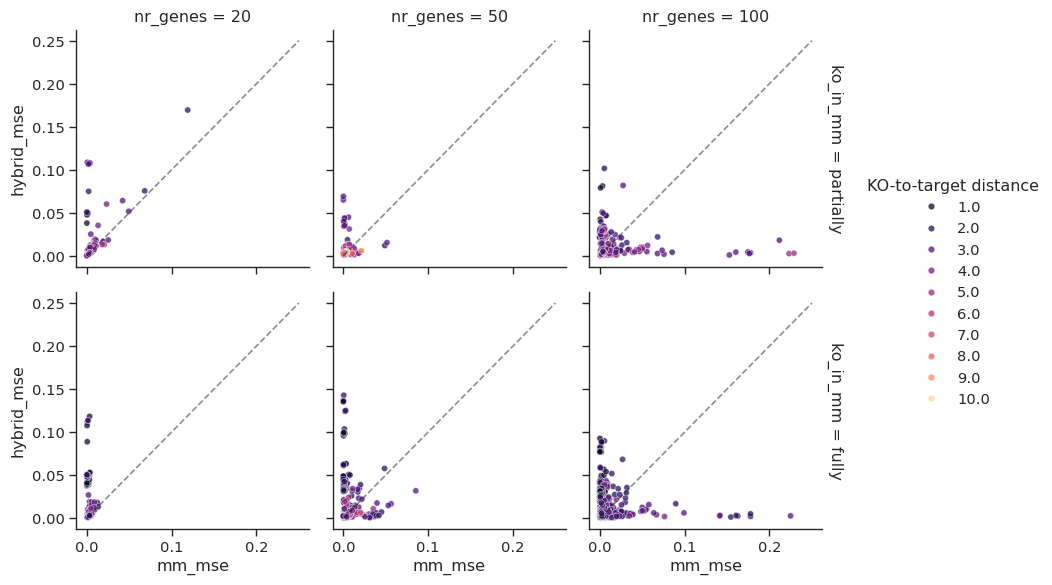

In [30]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mm_mse', y='hybrid_mse', row='ko_in_mm', col='nr_genes', hue='KO-to-target distance', palette=custom_palette,# legend=False,
                  alpha=.75, s=20, height=3, aspect=1, col_order=natsorted(paired['nr_genes'].unique()), facet_kws={'margin_titles': True})
# g.figure.set_size_inches(6, 3) 
# g.set(xscale="log", yscale="log")
for ax in g.axes.flat:
    ax.plot([0, .25], [0, .25], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mm_vs_hybrid_lin.pdf", dpi=600, bbox_inches='tight')

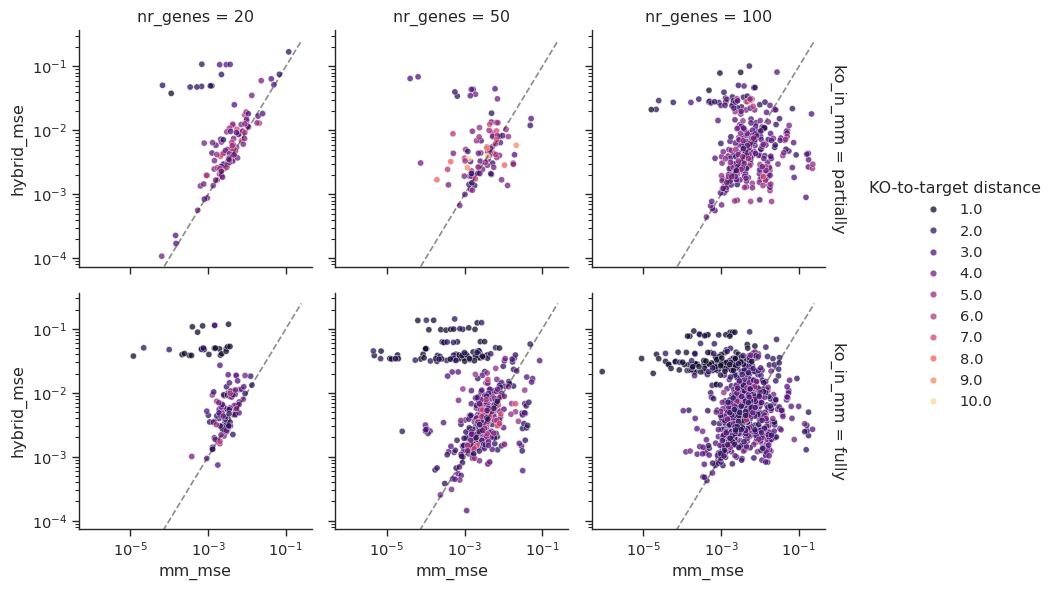

In [31]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mm_mse', y='hybrid_mse', row='ko_in_mm', col='nr_genes', hue='KO-to-target distance', palette=custom_palette,# legend=False,
                  alpha=.75, s=20, height=3, aspect=1, col_order=natsorted(paired['nr_genes'].unique()), facet_kws={'margin_titles': True})
# g.figure.set_size_inches(6, 3) 
g.set(xscale="log", yscale="log")
for ax in g.axes.flat:
    ax.plot([0, .25], [0, .25], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mm_vs_hybrid_log.pdf", dpi=600, bbox_inches='tight')